# Práctica - Regresión lineal utilizando mínimos cuadrados

En este práctica se pretende realizar un modelo de regresión lineal usando mínimos cuadrados sobre un conjunto de datos sintéticos.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

Se genera un conjunto de datos empleando el módulo *random*, muestreando unformemente 1000 ejemplos entre -5 y 5. Adicionalmente, se genera los valores de los parámetros de nuestra función. Finalmente, se agrega ruido Gaussiano.


In [2]:
# 1000 muestras de dos dimensiones usando una distribución uniforme
X = np.random.uniform(-5,5,(1000,2))

Se fijan los parámetros $\boldsymbol{\theta}$ manualmente a $[3, -1.0]$

In [3]:
# Generamos los valores de nuestros parámetros
theta = np.array([[3.0], [-1.0]])

Se supone un modelo lineal con dos atributos, esto es,

$$
y_{i}=f_{\mathbf{\theta}}(x_{1},x_{2}) = \theta_{1}x_{1}+\theta_{2}x_{2}+\epsilon,
$$

In [4]:
Y = X.dot(theta) + np.random.normal(loc=0.0, scale=0.1, size=(1000,1))

La notación vectorial de la última expresión puede ser escrita como:

$$
f_{\mathbf{\theta}}(\mathbf{x}) = \boldsymbol{\theta}^\top \mathbf{x}+\mathbf{\epsilon},
$$

donde $\boldsymbol{\theta}$, $\mathbf{x}$ y $\mathbf{\epsilon}$ son vectores columna.

Los datos generados son graficados como

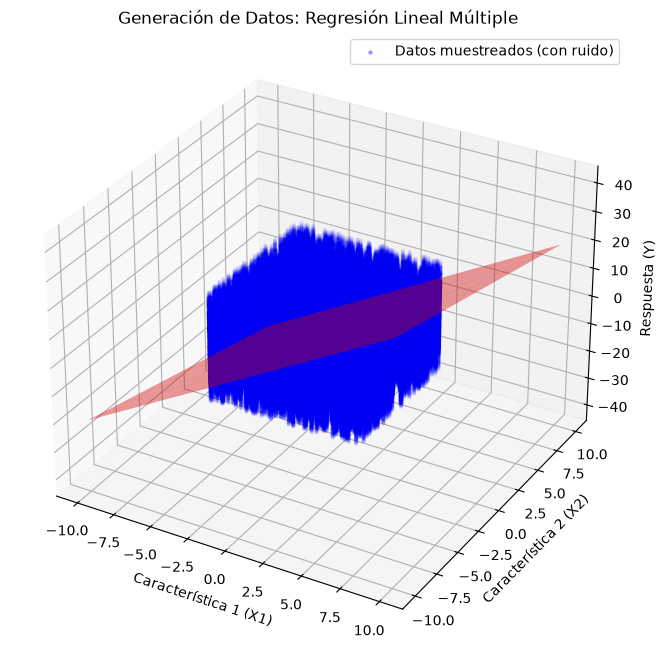

In [ ]:
# 3. Configurar la visualización 3D
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Dispersión de los datos sintéticos con ruido
ax.scatter(X[:, 0], X[:, 1], Y, c='blue', marker='.', alpha=0.3, label='Datos muestreados (con ruido)')

# 4. (Opcional) Graficar el plano ideal sin ruido
x1_rango = np.linspace(-10, 10, 10)
x2_rango = np.linspace(-10, 10, 10)
x1_malla, x2_malla = np.meshgrid(x1_rango, x2_rango)
y_malla = x1_malla * theta[0, 0] + x2_malla * theta[1, 0]

ax.plot_surface(x1_malla, x2_malla, y_malla, color='red', alpha=0.4)

# Etiquetas
ax.set_xlabel('Característica 1 (X1)')
ax.set_ylabel('Característica 2 (X2)')
ax.set_zlabel('Respuesta (Y)')
ax.set_title('Generación de Datos: Regresión Lineal Múltiple')
plt.legend()
plt.show()

# Actividades:

1. Particionar conjunto de datos en entrenamiento y prueba (Método Hold-out).
2. Definir una función predictora $y$.
3. Estimar los parámetros empleando mínimos cuadrados sobre el conjunto de entrenamiento:
$$
\boldsymbol{\theta} = (\mathbf{X}^\top \mathbf{X})^{-1} \mathbf{X}^\top \mathbf{y}
$$
4. Realizar las predicciones sobre el conjunto de prueba.
5. Definir la función de pérdida basada en el error cuadrático medio y obtener dicho error sobre el conjunto de prueba.
$$
E(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^N (y_{i}-f_{\mathbf{\theta}}(\mathbf{x}_{i}))^2
$$
6. Graficar el ajuste del predictor sobre el conjunto de datos entrenamiento y prueba.

## Solución de las actividades

### 1. Partición del conjunto de datos (Hold-out)

Se mezclan los índices al azar y se usa 80 % de los datos para entrenar y 20 % para probar.

In [6]:
np.random.seed(42)                      # para que los resultados se puedan repetir
N = X.shape[0]
indices = np.random.permutation(N)      # índices mezclados al azar

n_train = int(0.8 * N)                  # 80 % entrenamiento
idx_train, idx_test = indices[:n_train], indices[n_train:]

X_train, Y_train = X[idx_train], Y[idx_train]
X_test,  Y_test  = X[idx_test],  Y[idx_test]

print("Entrenamiento:", X_train.shape, Y_train.shape)
print("Prueba:       ", X_test.shape, Y_test.shape)

Entrenamiento: (800, 2) (800, 1)
Prueba:        (200, 2) (200, 1)


### 2. Función predictora

$$f_{\boldsymbol{\theta}}(\mathbf{x}) = \mathbf{X}\boldsymbol{\theta}$$

In [7]:
def predecir(X, theta):
    """Función predictora lineal: y = X · theta"""
    return X.dot(theta)

### 3. Estimación de los parámetros con mínimos cuadrados

$$\boldsymbol{\theta} = (\mathbf{X}^\top \mathbf{X})^{-1} \mathbf{X}^\top \mathbf{y}$$

Solo se usa el conjunto de **entrenamiento**.

In [8]:
def minimos_cuadrados(X, Y):
    return np.linalg.inv(X.T.dot(X)).dot(X.T).dot(Y)

theta_est = minimos_cuadrados(X_train, Y_train)

print("theta real:      ", theta.ravel())
print("theta estimado:  ", theta_est.ravel())

theta real:       [ 3. -1.]
theta estimado:   [ 3.00194594 -0.99888682]


### 4. Predicciones sobre el conjunto de prueba

In [9]:
Y_pred_test = predecir(X_test, theta_est)
Y_pred_train = predecir(X_train, theta_est)

print("Primeras 5 predicciones vs. valores reales (prueba):")
for real, pred in zip(Y_test[:5].ravel(), Y_pred_test[:5].ravel()):
    print(f"  real = {real:8.4f}   predicho = {pred:8.4f}")

Primeras 5 predicciones vs. valores reales (prueba):
  real = -12.0680   predicho = -11.8769
  real = -14.1356   predicho = -14.2771
  real =  10.5601   predicho =  10.6333
  real = -13.2528   predicho = -13.2641
  real = -16.2270   predicho = -16.2393


### 5. Función de pérdida (error cuadrático medio)

$$E(\boldsymbol{\theta}) = \frac{1}{N}\sum_{i=1}^N (y_{i}-f_{\mathbf{\theta}}(\mathbf{x}_{i}))^2$$

In [10]:
def ecm(Y_real, Y_pred):
    return np.mean((Y_real - Y_pred) ** 2)

print(f"ECM entrenamiento: {ecm(Y_train, Y_pred_train):.6f}")
print(f"ECM prueba:        {ecm(Y_test,  Y_pred_test):.6f}")

ECM entrenamiento: 0.009968
ECM prueba:        0.011292


El ruido que se agregó tiene desviación estándar 0.1, o sea varianza $0.1^2 = 0.01$. Por eso un ECM cercano a 0.01 significa que el modelo ajustó casi perfecto: lo único que no puede explicar es el ruido.

### 6. Gráfica del ajuste (entrenamiento y prueba)

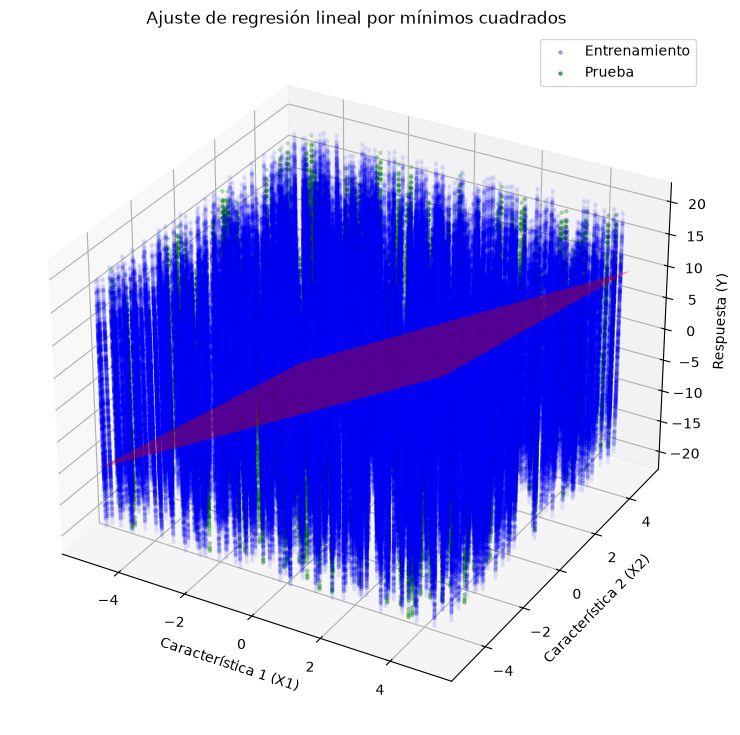

In [ ]:
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_train[:, 0], X_train[:, 1], Y_train, c='blue', marker='.', alpha=0.3, label='Entrenamiento')
ax.scatter(X_test[:, 0],  X_test[:, 1],  Y_test,  c='green', marker='.', alpha=0.6, label='Prueba')

# Plano ajustado por el modelo
x1_rango = np.linspace(-5, 5, 10)
x2_rango = np.linspace(-5, 5, 10)
x1_malla, x2_malla = np.meshgrid(x1_rango, x2_rango)
y_malla = x1_malla * theta_est[0, 0] + x2_malla * theta_est[1, 0]
ax.plot_surface(x1_malla, x2_malla, y_malla, color='red', alpha=0.4)

ax.set_xlabel('Característica 1 (X1)')
ax.set_ylabel('Característica 2 (X2)')
ax.set_zlabel('Respuesta (Y)')
ax.set_title('Ajuste de regresión lineal por mínimos cuadrados')
plt.legend()
plt.savefig("grafica_p01.png", dpi=150, bbox_inches="tight")
plt.show()